# ¿Se aprueba un préstamo?

**Versión completa: los 5 cuadernillos seguidos**

**Autor:** Dilan Aldana - Jeison Del Rio

**Objetivo.** Predecir si una solicitud de crédito se aprueba (`Y`) o se rechaza (`N`) y explicar qué variables pesan en esa decisión, para que el banco pueda priorizar la revisión de solicitudes.

**Fecha:** 22 de noviembre de 2026

**Desarrollo.** Este documento reúne los cinco cuadernillos del proyecto en un solo archivo. Cada uno conserva su objetivo, su desarrollo y su conclusión, y se puede abrir por separado en la carpeta `notebooks/`:

1. **Mirar los datos:** qué contiene el archivo, qué falta y cómo se reparten las clases.
2. **Análisis exploratorio:** cada variable por separado, contra la aprobación y en conjunto.
3. **Limpieza y separación:** registros imposibles, transformación y división entrenamiento/prueba.
4. **Modelos y matrices de confusión:** comparación, matriz inicial, ajuste de `C` y matriz nueva.
5. **Interpretación y conclusión:** coeficientes, caso individual, guardado y cierre.

Cada gráfico, tabla y resultado va seguido de una explicación en lenguaje sencillo.

In [1]:
# Python básico
import sys
import warnings
from pathlib import Path

# Datos y gráficos
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Modelos y métricas
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from funciones import analisis
from funciones.analisis import AZUL, ROJO

warnings.filterwarnings("ignore")
analisis.configurar_estilo()

print("Todo listo")

Todo listo


## Cuadernillo 1 · Mirar los datos

**Qué hace esta celda.** Deja listas las herramientas: `pandas` para manejar tablas, `analisis` con las funciones del proyecto y `Path` para ubicar la carpeta. No calcula nada todavía.

### 1. Cargar el archivo

El banco entrega los datos en un **CSV**, un archivo de texto donde cada línea es una solicitud y las columnas se separan con comas. `pandas` lo convierte en una tabla (`df`).

In [2]:
df = pd.read_csv(RAIZ / "datos" / "solicitudes_prestamos.csv")

print(f"Filas: {len(df)}   Columnas: {df.shape[1]}")
df.head(5)

Filas: 614   Columnas: 13


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


La tabla tiene **614 solicitudes** (filas) y **13 columnas**. Cada fila es un caso y cada columna un dato de ese caso: ingresos y monto del préstamo (números), sexo, estado civil, educación, empleo y zona (texto), `Loan_ID` (un código único, como un número de radicado) y `Loan_Status` (la respuesta: `Y` aprobado, `N` rechazado), que es lo que el modelo debe predecir.

### 2. Valores faltantes

Un **nulo** es una casilla que el banco no registró. La celda cuenta cuántos hay en cada columna.

In [3]:
print("Valores faltantes por columna:")
display(analisis.resumen_nulos(df))

Valores faltantes por columna:


,nulos,porcentaje
Credit_History,50,8.1
Self_Employed,32,5.2
LoanAmount,22,3.6
Dependents,15,2.4
Loan_Amount_Term,14,2.3
Gender,13,2.1
Married,3,0.5


**7 de las 13 columnas tienen huecos.** La más incompleta es `Credit_History` (50), seguida de `Self_Employed` (32), `LoanAmount` (22) y `Dependents` (15).

Borrarlas costaría **134 solicitudes (21,8 %)**, casi una de cada cinco. Por eso no se eliminan: los huecos se **imputan** (se rellenan con la mediana) dentro del modelo (cuadernillos 3 y 4).

### 3. Duplicados y variable objetivo

Se revisa si hay solicitudes repetidas y cómo se reparten las respuestas. `Loan_Status` es la **variable objetivo**.

In [4]:
print("¿Cuántas solicitudes se aprobaron?")
print(df["Loan_Status"].value_counts())
print(f"\nPorcentaje aprobado: {df['Loan_Status'].eq('Y').mean() * 100:.1f}%")
print("Filas duplicadas:", df.duplicated().sum())

¿Cuántas solicitudes se aprobaron?
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Porcentaje aprobado: 68.7%
Filas duplicadas: 0


Hay **422 aprobadas (68,7 %)** y **192 rechazadas (31,3 %)**, y ninguna fila repetida.

Esa diferencia se llama **desbalanceo**. Si el modelo dijera siempre "aprobado", acertaría el 68,7 % sin haber aprendido nada y no detectaría ningún rechazo. Para evitarlo, al entrenar se le da más peso a la clase minoritaria con `class_weight="balanced"` (cuadernillo 4).

### 4. Conclusión

- El archivo tiene **614 solicitudes y 13 columnas**; `Loan_ID` es solo un código y se quitará (cuadernillo 3).
- **7 columnas tienen huecos** y 134 filas (21,8 %) tienen al menos uno. Se imputan con la mediana en vez de borrarlas (cuadernillos 3 y 4).
- Las clases están **desbalanceadas (68,7 % / 31,3 %)** y se compensan con `class_weight="balanced"` (cuadernillo 4).

Los datos sirven, pero hay que limpiarlos y tratarlos antes de entrenar.

## Cuadernillo 2 · Análisis exploratorio

**Qué hace esta celda.** Carga los gráficos, las funciones del proyecto y el estilo común. No calcula nada.

### Preparación

Se lee el archivo y se crea `Aprobado`: **1 = aprobado, 0 = rechazado**. Los modelos necesitan números, no letras.

In [5]:
df = pd.read_csv(RAIZ / "datos" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

print(f"Filas: {len(df)}   Columnas: {df.shape[1]}")
print(df["Aprobado"].value_counts().rename({1: "Aprobado", 0: "Rechazado"}))

Filas: 614   Columnas: 14
Aprobado
Aprobado     422
Rechazado    192
Name: count, dtype: int64


Se mantienen las **614 solicitudes**; `Aprobado` tiene 422 unos y 192 ceros. Con 1 y 0, el promedio de la columna es directamente la tasa de aprobación.

### 1. Análisis de una variable (univariado)

Cada variable por separado, para ver su forma antes de cruzarla con otras.

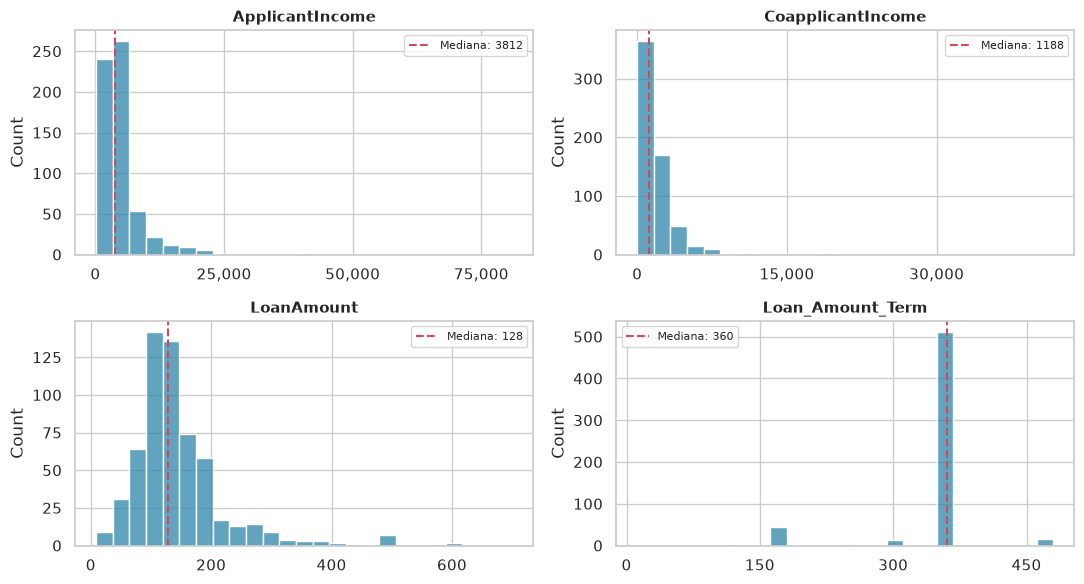

In [6]:
analisis.graficar_numericas(
    df, ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
)

**Variables numéricas.** Los ingresos están **estirados hacia la derecha**: la mediana es 3.812, pero el promedio sube a 5.403 por unos pocos ingresos muy altos (el máximo es 81.000). El **44,5 % no tiene codeudor** y la mitad de los préstamos está entre 100 y 168. El **83,4 % pide 360 meses**: el plazo casi no distingue entre solicitudes.

Por esos valores extremos, las variables se **escalan** antes de entrenar (cuadernillo 4) y los huecos se rellenan con la **mediana** (cuadernillo 3), que no se deja arrastrar por ellos.

#### Variables categóricas

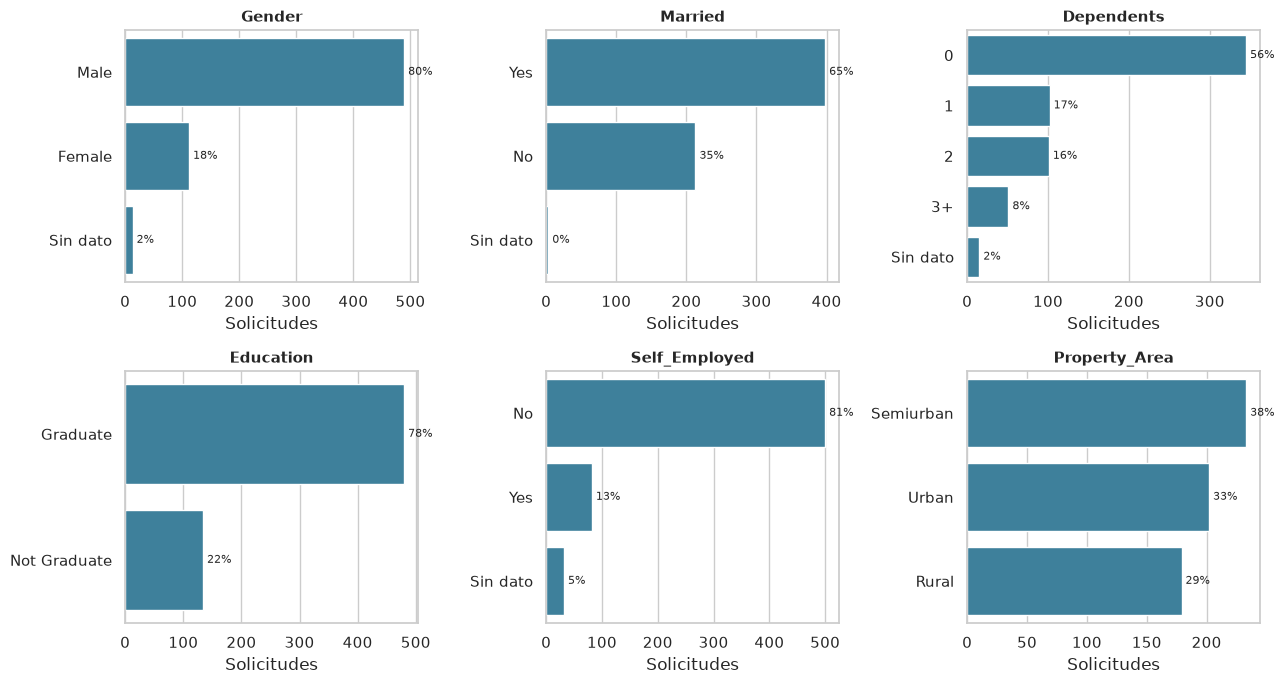

In [7]:
analisis.graficar_categoricas(
    df, ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]
)

Ninguna categoría es demasiado pequeña: género (79,6 % hombres), estado civil (64,8 % casados), dependientes (56,2 % sin dependientes), educación (78,2 % universitarios), empleo (81,4 % asalariados) y zona (37,9 % semiurbana, 32,9 % urbana, 29,2 % rural).

Los casos sin dato (2,1 % en género, 0,5 % en estado civil, 5,2 % en empleo) no se borran: quedan como categoría `"Sin dato"` (cuadernillo 3).

### 2. Análisis de dos variables (bivariado)

Se cruza cada variable con la respuesta: cada barra es la tasa de aprobación de un grupo y la línea roja, el promedio general (68,7 %).

Tasa de aprobación según historial crediticio:
Historial
Con historial    79.6
Sin dato         74.0
Sin historial     7.9
Name: Aprobado, dtype: float64

Tasa de aprobación según zona:
Property_Area
Rural        61.5
Semiurban    76.8
Urban        65.8
Name: Aprobado, dtype: float64


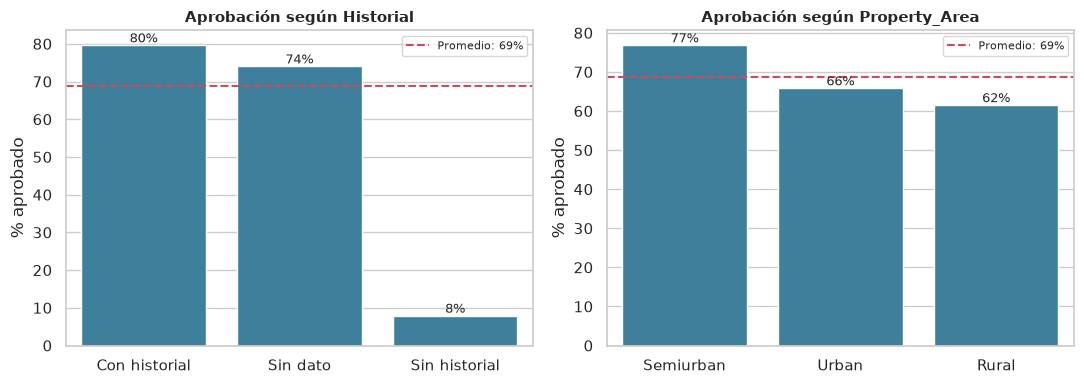

In [8]:
# Una versión con nombres claros solo para los gráficos
df_plot = df.assign(
    Historial=df["Credit_History"].map({0.0: "Sin historial", 1.0: "Con historial"})
                        .fillna("Sin dato")
)

print("Tasa de aprobación según historial crediticio:")
print(analisis.tasa_aprobacion(df_plot, "Historial"))
print()
print("Tasa de aprobación según zona:")
print(analisis.tasa_aprobacion(df, "Property_Area"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
analisis.graficar_tasa_aprobacion(df_plot, "Historial", axes[0])
analisis.graficar_tasa_aprobacion(df, "Property_Area", axes[1])
plt.tight_layout()
plt.show()

**Historial crediticio.** La diferencia es enorme: **con historial se aprueba el 79,6 %; sin historial, solo el 7,9 %**. Las 50 solicitudes sin el dato (`Sin dato`) se aprueban el 74 %, parecido a quienes sí tienen historial; por eso se imputan en lugar de borrarse (cuadernillo 3).

**Zona.** Va de **61,5 % en rural a 76,8 % en semiurbana**: hay diferencia, pero mucho menor. El historial es el primer filtro; la zona ajusta.

### 3. Análisis de varias variables (multivariado)

Varias variables a la vez, para responder dos cosas: si alguna repite información de otra y cómo se combinan el historial y la zona.

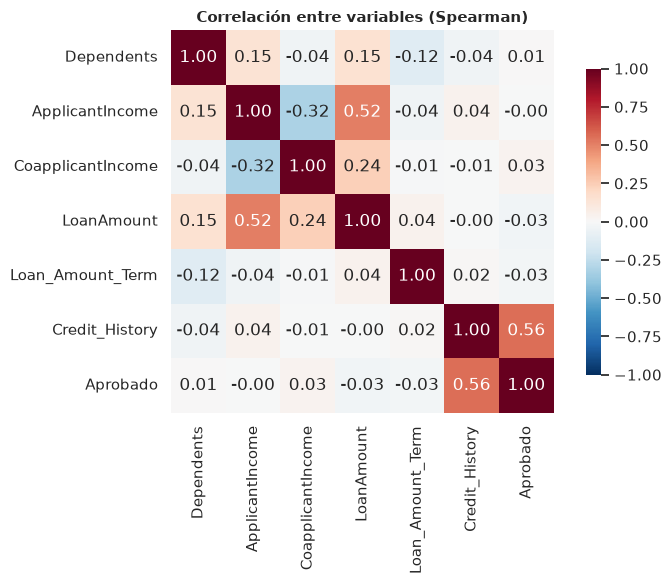

Correlación con la aprobación:
Credit_History       0.56
LoanAmount          -0.03
CoapplicantIncome    0.03
Loan_Amount_Term    -0.03
Dependents           0.01
ApplicantIncome     -0.00
Name: Aprobado, dtype: float64


In [9]:
# Se convierte "3+" solo para poder calcular correlaciones
df_num = df.assign(Dependents=df["Dependents"].replace("3+", "3").astype(float))

columnas_num = ["Dependents", "ApplicantIncome", "CoapplicantIncome",
                "LoanAmount", "Loan_Amount_Term", "Credit_History", "Aprobado"]

correlacion = analisis.graficar_correlacion(df_num, columnas_num)

print("Correlación con la aprobación:")
print(correlacion["Aprobado"].drop("Aprobado").sort_values(key=abs, ascending=False).round(2))

**Mapa de correlaciones.** Cada celda es un número entre −1 y 1 que mide si dos variables se mueven juntas: cerca de 1, suben a la vez; cerca de −1, una sube cuando la otra baja; cerca de 0, no hay relación lineal. El rojo indica relación positiva, el azul negativa y el blanco ausencia de relación. La última fila y la última columna son las que importan, porque cruzan todo con `Aprobado`.

- Solo **`Credit_History` (0,56)** se acerca de forma clara a la aprobación. Las demás quedan entre −0,03 y 0,03.
- Entre predictoras, la relación más alta es **ingreso ↔ monto (0,68)**: quien gana más suele pedir más. No llega a 0,8, así que no son dos copias y no hay que eliminar ninguna.

Que una variable tenga correlación baja no la vuelve inútil: solo dice que, sola, no acompaña de forma lineal a la aprobación.

In [10]:
print("Aprobación combinando zona e historial crediticio:")

tabla_cruzada = pd.crosstab(
    df["Property_Area"], df["Credit_History"],
    values=df["Aprobado"], aggfunc="mean",
).round(2)
tabla_cruzada.columns = ["Sin historial", "Con historial"]
tabla_cruzada

Aprobación combinando zona e historial crediticio:


,Sin historial,Con historial
Property_Area,,
Rural,0.07,0.72
Semiurban,0.13,0.88
Urban,0.03,0.77


**Zona + historial.** Con historial, la aprobación va de **72 % (rural) a 88 % (semiurbana)**. Sin historial, ninguna zona supera el **13 %**. La zona solo marca diferencias cuando ya hay historial: el historial decide si hay conversación y la zona ajusta el resultado.

### 4. Conclusión

- **`Credit_History` es la variable decisiva:** 79,6 % de aprobación con historial frente a 7,9 % sin historial, y la única correlación alta con la respuesta (0,56).
- **La zona ajusta, no decide:** importa solo cuando ya hay historial (72 % a 88 %); sin historial, ninguna zona pasa del 13 %.
- **Los ingresos están estirados y el plazo es casi constante** (83,4 % a 30 años): aportan poco y hay que escalarlos (cuadernillo 4).
- **No hay variables redundantes:** la relación más alta entre predictoras es 0,68 y no obliga a eliminar ninguna.

Se espera que un modelo sencillo apoyado en el historial funcione bien. Se comprueba en el cuadernillo 4.

## Cuadernillo 3 · Limpieza y separación

**Qué hace esta celda.** Carga `pandas`, `train_test_split` (la función que divide los datos) y ubica la carpeta del proyecto.

### 1. Cargar el archivo

Se lee el archivo y se crea `Aprobado`: **1 = aprobado, 0 = rechazado**.

In [11]:
df = pd.read_csv(RAIZ / "datos" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

print(f"Filas: {len(df)}   Columnas: {df.shape[1]}")
print(df["Aprobado"].value_counts().rename({1: "Aprobado", 0: "Rechazado"}))

Filas: 614   Columnas: 14
Aprobado
Aprobado     422
Rechazado    192
Name: count, dtype: int64


Quedan **614 solicitudes** con **422 aprobadas y 192 rechazadas** en `Aprobado`. La tabla tiene ahora 14 columnas porque se sumó esa columna a las 13 originales.

### 2. Revisar registros sin sentido

Antes de transformar se buscan valores imposibles, que el modelo no debería aprender. La celda aplica cinco reglas:

| Regla | Qué detecta |
|---|---|
| Ingresos negativos | Alguien que gana menos de cero |
| Monto del préstamo <= 0 | Un préstamo de cero o negativo |
| Plazo <= 0 | Un plazo de cero o negativo |
| Dependientes fuera de 0 a 3 | Un número imposible de dependientes |
| `Credit_History` distinto de 0 o 1 | Un historial que no es "sí" ni "no" |

In [12]:
reglas = {
    "Ingresos negativos": df["ApplicantIncome"] < 0,
    "Monto del préstamo <= 0": df["LoanAmount"] <= 0,
    "Plazo <= 0": df["Loan_Amount_Term"] <= 0,
    "Dependientes fuera de 0 a 3": (
        ~df["Dependents"].isin(["0", "1", "2", "3+"])
        & df["Dependents"].notna()
    ),
    "Credit_History distinto de 0 o 1": (
        ~df["Credit_History"].isin([0, 1])
        & df["Credit_History"].notna()
    ),
}

pd.Series(
    {nombre: casos.sum() for nombre, casos in reglas.items()},
    name="casos",
)

Ingresos negativos                  0
Monto del préstamo <= 0             0
Plazo <= 0                          0
Dependientes fuera de 0 a 3         0
Credit_History distinto de 0 o 1    0
Name: casos, dtype: int64

Las cinco reglas dan **0 casos**: ninguna solicitud tiene un valor imposible, así que no hay que borrar ni corregir filas.

### 3. Transformar las variables

Cuatro cambios, cada uno con su motivo:

1. **Quitar `Loan_ID`:** es un código único y no ayuda a predecir; dejarlo permitiría al modelo memorizar identificadores.
2. **Convertir `"3+"` en 3:** los modelos necesitan números.
3. **Marcar los huecos de texto como `"Sin dato"`:** en vez de inventar una categoría, queda explícito que el dato falta.
4. **Unir los ingresos en `Ingreso_Total`:** para pagar la cuota importa lo que entra al hogar, no quién lo aporta.

Los huecos numéricos (`LoanAmount`, `Loan_Amount_Term`, `Credit_History`, `Dependents`) **no se rellenan aquí**: se imputan dentro del modelo (cuadernillo 4).

In [13]:
# Quitar el identificador
df = df.drop(columns="Loan_ID")

# Dependents: "3+" se convierte en 3
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)

# Categóricas vacías: se marcan como "Sin dato"
for columna in ["Gender", "Married", "Self_Employed"]:
    df[columna] = df[columna].fillna("Sin dato")

# Una sola variable de ingreso
df["Ingreso_Total"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df = df.drop(columns=["ApplicantIncome", "CoapplicantIncome"])

print(f"Columnas ahora: {df.shape[1]}")
print("\nNulos que quedan (se imputan en el modelo):")
print(df.isna().sum()[df.isna().sum() > 0])

Columnas ahora: 12

Nulos que quedan (se imputan en el modelo):
Dependents          15
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64


Quedan **12 columnas**. Siguen con huecos `Dependents` (15), `LoanAmount` (22), `Loan_Amount_Term` (14) y `Credit_History` (50).

Se rellenan después de separar porque la mediana debe salir **solo de entrenamiento**: si se calculara con todo, el modelo vería información del examen antes de presentarlo (**fuga de información**) y las métricas se verían mejores de lo que son.

### 4. Separar entrenamiento y prueba

El modelo aprende con un grupo y se evalúa con otro que nunca vio; si se evaluara con los mismos datos, sería como darle el examen con las respuestas.

- **80 % para entrenar (491):** el modelo aprende de estos casos.
- **20 % para probar (123):** se guardan como examen final.

La división es **estratificada** (misma proporción de aprobados en ambos grupos) y `random_state=42` la deja fija para que cualquiera obtenga los mismos resultados.

In [14]:
y = df.pop("Aprobado")
X = pd.get_dummies(df.drop(columns="Loan_Status"), drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} solicitudes")
print(f"Prueba:        {X_test.shape[0]} solicitudes")
print(f"Columnas para el modelo: {X.shape[1]}")
print(f"\nAprobados en entrenamiento: {y_train.mean() * 100:.1f}%")
print(f"Aprobados en prueba:        {y_test.mean() * 100:.1f}%")

Entrenamiento: 491 solicitudes
Prueba:        123 solicitudes
Columnas para el modelo: 14

Aprobados en entrenamiento: 68.6%
Aprobados en prueba:        69.1%


**491 para entrenar y 123 para probar.** En entrenamiento se aprueba el **68,6 %** y en prueba el **69,1 %**: la proporción quedó pareja y la comparación será justa.

El grupo de prueba no se usa para imputar, escalar ni elegir hiperparámetros. Solo se usa para medir (cuadernillo 4), así que las métricas reflejan datos que el modelo nunca vio.

### 5. Conclusión

- **0 registros imposibles:** las cinco reglas no encontraron casos, así que no hubo que borrar filas.
- **10 variables originales → 14 columnas:** se quitó `Loan_ID`, `"3+"` pasó a 3, los huecos de texto quedaron como `"Sin dato"` y los ingresos se unieron en `Ingreso_Total`.
- **División 491 / 123, estratificada:** 68,6 % y 69,1 % de aprobación, prácticamente iguales.
- **La imputación queda para el modelo** (cuadernillo 4), calculada solo con entrenamiento, para no contaminar la evaluación.

Con los datos limpios y separados, el cuadernillo 4 puede comparar modelos.

## Cuadernillo 4 · Modelos y matrices de confusión

**Qué hace esta celda.** Prepara los modelos y métricas de `scikit-learn`, los gráficos y las funciones del proyecto. `Pipeline` encadena pasos y `GridSearchCV` prueba configuraciones.

### Preparación

Esta celda repite los pasos de los cuadernillos 1 a 3 (leer, limpiar, transformar y separar). En esta versión completa los datos ya están cargados, así que solo deja todo listo antes de entrenar.

In [15]:

# Preparación: se repiten los pasos de los cuadernillos 1 a 3
# para que este cuaderno funcione solo.
df = pd.read_csv(RAIZ / "datos" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

df = df.drop(columns="Loan_ID")
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)
for columna in ["Gender", "Married", "Self_Employed"]:
    df[columna] = df[columna].fillna("Sin dato")

df["Ingreso_Total"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df = df.drop(columns=["ApplicantIncome", "CoapplicantIncome"])

y = df.pop("Aprobado")
X = pd.get_dummies(df.drop(columns="Loan_Status"), drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} solicitudes")
print(f"Prueba:        {X_test.shape[0]} solicitudes")
print(f"Variables:     {X.shape[1]}")


Entrenamiento: 491 solicitudes
Prueba:        123 solicitudes
Variables:     14


Los datos quedan como al final del cuadernillo 3: **491 para entrenar, 123 para probar y 14 columnas**.

### 1. Los modelos

- **Base:** dice siempre "aprobado". No aprende; sirve para saber cuánto mejora un modelo real.
- **Regresión logística:** calcula una probabilidad a partir de las variables. Es lineal y se puede explicar.
- **Random Forest:** cientos de árboles que votan. Capta relaciones complejas, pero con pocos datos puede memorizar.

Cada uno se entrena con 491 solicitudes y se evalúa con las 123 que no vio.

In [16]:
def crear_logistica(C=1):
    """Pipeline de regresión logística; C controla la regularización."""
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", LogisticRegression(
            C=C, max_iter=2000, class_weight="balanced", random_state=42
        )),
    ])


modelos = {
    "Base (siempre aprueba)": Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", DummyClassifier(strategy="most_frequent")),
    ]),

    "Regresión logística": crear_logistica(),

    "Random Forest": Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("modelo", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                          random_state=42, n_jobs=-1)),
    ]),
}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    resultados.append(analisis.evaluar(nombre, modelo, X_train, y_train, X_test, y_test))

tabla = analisis.tabla_resultados(resultados)
tabla

,modelo,auc_train,auc_test,brecha,exactitud,precision,recall,f1
1,Regresión logística,0.767,0.851,-0.084,0.829,0.872,0.882,0.877
2,Random Forest,1.000,0.826,0.174,0.780,0.854,0.824,0.838
0,Base (siempre aprueba),0.500,0.500,0.000,0.691,0.691,1.000,0.817


**Cómo se lee la tabla.** **AUC** mide qué tan bien ordena las solicitudes de más a menos probable (0,50 = azar, 1,00 = perfecto). **Exactitud** es el porcentaje de aciertos. **Recall** es la proporción de aprobados que detecta. **F1** combina precisión y recall. **Brecha** es la diferencia entre el AUC de entrenamiento y el de prueba: si es grande, el modelo memorizó.

La **regresión logística** gana (AUC 0,851, exactitud 82,9 %). El **base** acierta 69,1 % solo porque la mayoría se aprueba; su AUC de 0,50 muestra que no distingue nada. El **Random Forest** queda atrás (0,826) con una brecha de **+0,174**.

También pesa que la logística se puede explicar, algo importante cuando hay que justificar un rechazo (cuadernillo 5).

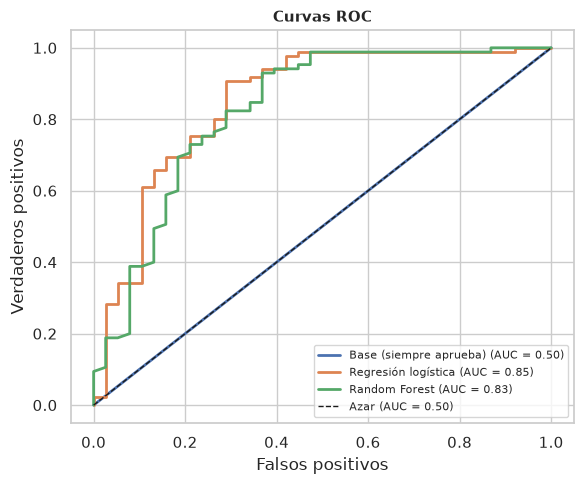

In [17]:
analisis.graficar_roc(modelos, X_test, y_test)

**Curva ROC.** Cada punto representa un punto de corte distinto para aprobar. El eje horizontal son los **falsos positivos** (rechazados que el modelo aprobaría) y el vertical, los **verdaderos positivos** (aprobados que detecta). La diagonal es adivinar al azar.

Cuanto más arriba y a la izquierda queda la curva (muchos aciertos con pocos falsos positivos), mejor separa el modelo. El área bajo la curva (**AUC**) resume eso en un número.

La logística (AUC 0,85) y el Random Forest (0,83) están cerca y muy por encima del azar. El AUC compara modelos en general, pero no dice cuántos errores concretos se cometen: para eso está la matriz (sección 2).

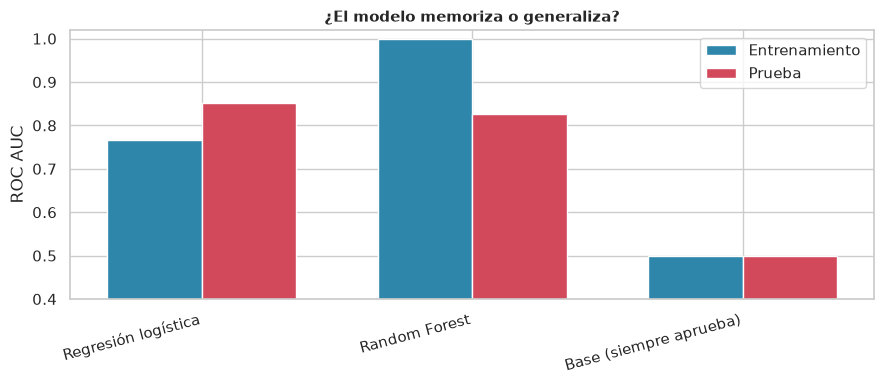

In [18]:
analisis.graficar_train_test(tabla)

**Qué muestra.** Compara el AUC de entrenamiento (azul) con el de prueba (rojo).

El **Random Forest** saca 1,00 en entrenamiento y 0,83 en prueba: la caída de 17 puntos es **sobreajuste**, aprendió de memoria. La **logística** va de 0,77 a 0,85: rinde igual o mejor con datos nuevos. Por eso se descarta el bosque y se sigue con la logística.

### 2. Matriz de confusión del modelo

El AUC resume en un número, pero no dice **qué tipo de error** se comete. La matriz cruza la predicción con la realidad y reparte las 123 solicitudes de prueba en cuatro casillas. Se evalúa la logística en su configuración inicial (`C = 1`).

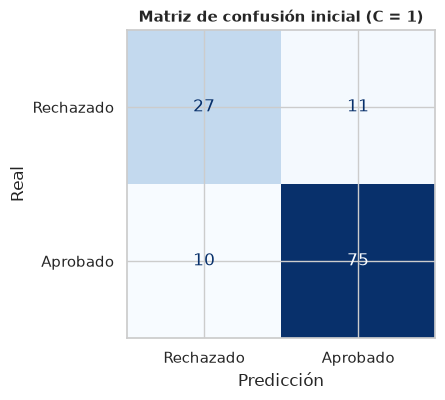

,casilla,significado,casos
0,Verdaderos negativos (TN),Rechazado y el modelo lo rechazó,27
1,Falsos positivos (FP),"Rechazado, pero el modelo lo aprobó",11
2,Falsos negativos (FN),"Aprobado, pero el modelo lo rechazó",10
3,Verdaderos positivos (TP),Aprobado y el modelo lo aprobó,75


              precision    recall  f1-score   support

   Rechazado      0.730     0.711     0.720        38
    Aprobado      0.872     0.882     0.877        85

    accuracy                          0.829       123
   macro avg      0.801     0.796     0.799       123
weighted avg      0.828     0.829     0.829       123



In [19]:
modelo_inicial = modelos["Regresión logística"]
prediccion_inicial = modelo_inicial.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, prediccion_inicial).ravel()

tabla_inicial = pd.DataFrame({
    "casilla": ["Verdaderos negativos (TN)", "Falsos positivos (FP)",
                "Falsos negativos (FN)", "Verdaderos positivos (TP)"],
    "significado": ["Rechazado y el modelo lo rechazó",
                    "Rechazado, pero el modelo lo aprobó",
                    "Aprobado, pero el modelo lo rechazó",
                    "Aprobado y el modelo lo aprobó"],
    "casos": [tn, fp, fn, tp],
})

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, prediccion_inicial,
    display_labels=["Rechazado", "Aprobado"],
    cmap="Blues",
    colorbar=False,
)
disp.ax_.set_xlabel("Predicción")
disp.ax_.set_ylabel("Real")
disp.ax_.set_title("Matriz de confusión inicial (C = 1)")
plt.show()

display(tabla_inicial)

print(classification_report(
    y_test, prediccion_inicial,
    target_names=["Rechazado", "Aprobado"],
    digits=3,
))

**Cómo se lee.** Filas = realidad, columnas = predicción. La diagonal son aciertos; las otras dos casillas, errores.

- **27 TN y 75 TP:** aciertos (rechazados y aprobados bien clasificados).
- **11 FP:** rechazados que el modelo aprobó.
- **10 FN:** aprobados que el modelo rechazó.

Acierta **102 de 123 (82,9 %)**.

**¿Dónde conviene enfocarse?** En los **falsos negativos**. Un FP no entrega el dinero: toda aprobación pasa por revisión de documentos, así que cuesta una revisión. Un FN termina el proceso: el cliente recibe un "no" y no hay revisión que lo recupere. Con un 68,7 % de aprobaciones, esos buenos clientes son la mayoría del negocio.

La métrica que mide eso es el **recall**: de los aprobados reales, cuántos detecta el modelo. Subirlo reduce los FN.

### 3. Ajuste de hiperparámetros

Un **hiperparámetro** es una configuración que se elige antes de entrenar, como una perilla. El único que se mueve es **`C`**, que controla la regularización: un `C` grande deja al modelo ajustarse mucho a los datos (riesgo de memorizar) y uno pequeño lo vuelve más prudente, con probabilidades menos extremas.

Se mantienen fijos `class_weight="balanced"` (compensación del desbalanceo, cuadernillo 1) y el corte de 0,5.

**Cómo se elige.** Con **validación cruzada de 5 partes**: el entrenamiento se divide en 5 grupos; se entrena con 4 y se prueba con el restante, rotando hasta que cada grupo sea prueba una vez, y se promedian los 5 resultados. Se optimiza **recall**, porque el foco son los FN; el AUC no dice cuántos aprobados quedan fuera con el corte de 0,5.

Hay un solo hiperparámetro con 6 valores, así que se prueban todos.

In [20]:
busqueda = GridSearchCV(
    crear_logistica(),
    {"modelo__C": [0.01, 0.05, 0.1, 0.5, 1, 10]},
    cv=5,
    scoring="recall",
    n_jobs=-1,
)

busqueda.fit(X_train, y_train)

print("Mejor valor de C:", busqueda.best_params_["modelo__C"])
print(f"Recall promedio en validación cruzada: {busqueda.best_score_:.3f}")

Mejor valor de C: 0.01
Recall promedio en validación cruzada: 0.920


El mejor valor es **`C = 0,01`**, con recall medio de **0,920** en las 5 vueltas. La regularización fuerte vuelve al modelo más prudente y reduce los rechazos indebidos.

In [21]:
tabla_cv = pd.DataFrame({
    "C": busqueda.cv_results_["param_modelo__C"].astype(float),
    "recall_medio": busqueda.cv_results_["mean_test_score"],
    "desviacion": busqueda.cv_results_["std_test_score"],
}).sort_values("C")

tabla_cv.round(3)

,C,recall_medio,desviacion
0,0.01,0.920,0.027
1,0.05,0.902,0.012
2,0.10,0.878,0.022
3,0.50,0.867,0.033
4,1.00,0.864,0.035
5,10.00,0.864,0.028


Cada fila es un valor de `C`; `recall_medio` promedia las 5 vueltas y `desviacion` indica cuánto varió. `C = 0,01` gana (0,920); al subir `C`, el recall baja hasta 0,864. La desviación es pequeña en todos, así que la diferencia no es casualidad.

In [22]:
modelo_final = busqueda.best_estimator_

comparacion = pd.DataFrame([
    analisis.evaluar("Logística con C=1", modelos["Regresión logística"],
                   X_train, y_train, X_test, y_test),
    analisis.evaluar(f"Logística con C={busqueda.best_params_['modelo__C']}",
                   modelo_final, X_train, y_train, X_test, y_test),
])
comparacion.round(3)

,modelo,auc_train,auc_test,exactitud,precision,recall,f1
0,Logística con C=1,0.767,0.851,0.829,0.872,0.882,0.877
1,Logística con C=0.01,0.765,0.844,0.846,0.851,0.941,0.894


**Qué cambió al pasar de C = 1 a C = 0,01**

- **Recall: 88,2 % → 94,1 %.** De cada 100 aprobados reales, detecta 94 en vez de 88.
- **Exactitud: 82,9 % → 84,6 %** y **F1: 0,877 → 0,894**.
- **Precisión: 87,2 % → 85,1 %.** Aprueba unas pocas más que estaban mal.
- **AUC: 0,851 → 0,844.** Una caída mínima, dentro de la variación de 123 casos.
- En validación cruzada también gana: **0,920** frente a **0,864**.

Al encoger los pesos, las probabilidades quedan más cerca de 0,5 y los casos dudosos tienden a aprobarse: bajan los FN y suben un poco los FP.

### 4. Nueva matriz de confusión

Se evalúa el modelo ajustado (`C = 0,01`) con las **mismas 123 solicitudes** y el **mismo corte de 0,5**. Solo cambió la configuración.

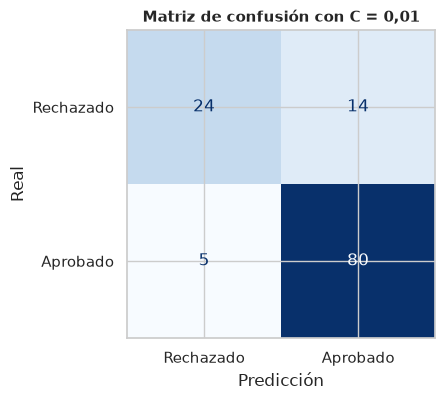

,casilla,C = 1,"C = 0,01",cambio
0,Verdaderos negativos (TN),27,24,-3
1,Falsos positivos (FP),11,14,3
2,Falsos negativos (FN),10,5,-5
3,Verdaderos positivos (TP),75,80,5


              precision    recall  f1-score   support

   Rechazado      0.828     0.632     0.716        38
    Aprobado      0.851     0.941     0.894        85

    accuracy                          0.846       123
   macro avg      0.839     0.786     0.805       123
weighted avg      0.844     0.846     0.839       123



In [23]:
modelo_final = busqueda.best_estimator_
prediccion_final = modelo_final.predict(X_test)

tn_f, fp_f, fn_f, tp_f = confusion_matrix(y_test, prediccion_final).ravel()

comparacion_matriz = pd.DataFrame({
    "casilla": ["Verdaderos negativos (TN)", "Falsos positivos (FP)",
                "Falsos negativos (FN)", "Verdaderos positivos (TP)"],
    "C = 1": [tn, fp, fn, tp],
    "C = 0,01": [tn_f, fp_f, fn_f, tp_f],
})
comparacion_matriz["cambio"] = (
    comparacion_matriz["C = 0,01"] - comparacion_matriz["C = 1"]
)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, prediccion_final,
    display_labels=["Rechazado", "Aprobado"],
    cmap="Blues",
    colorbar=False,
)
disp.ax_.set_xlabel("Predicción")
disp.ax_.set_ylabel("Real")
disp.ax_.set_title("Matriz de confusión con C = 0,01")
plt.show()

display(comparacion_matriz)

print(classification_report(
    y_test, prediccion_final,
    target_names=["Rechazado", "Aprobado"],
    digits=3,
))

- **FN: 10 → 5.** El cambio buscado: 5 clientes buenos que ya no se rechazan.
- **FP: 11 → 14.** El costo: 3 aprobaciones indebidas más, que la revisión de documentos debe detectar.
- **TP: 75 → 80** y **TN: 27 → 24.** El modelo se movió hacia aprobar.
- **Aciertos: 102 → 104 (82,9 % → 84,6 %).**

Se cambiaron 3 revisiones adicionales por 5 clientes recuperados. Si el banco prefiriera lo contrario, habría que dar más peso a los rechazados; el costo sería el inverso: más FN. Es una decisión de negocio y queda documentada.

### 5. Conclusión

- **Regresión logística:** el mejor modelo (AUC 0,851, exactitud 82,9 %, recall 88,2 %). El Random Forest sobreajustó (1,00 en entrenamiento, 0,83 en prueba) y se descartó.
- **Matriz inicial:** 10 falsos negativos, el error a atacar.
- **Ajuste de `C`:** optimizando recall con validación cruzada, el mejor valor fue **0,01** (recall 0,920 frente a 0,864).
- **Matriz nueva:** FN de 10 a 5, con 3 FP más; aciertos de 102 a 104 (82,9 % → 84,6 %).
- **Justificación:** un FP cuesta una revisión; un FN cuesta un cliente.

El cuadernillo 5 interpreta el modelo, explica una decisión concreta y lo guarda.

## Cuadernillo 5 · Interpretación y conclusión

**Qué hace esta celda.** Prepara `joblib` para guardar el modelo, los gráficos y las funciones del proyecto.

### Preparación

La celda repite los pasos de los cuadernillos 1 a 4 y entrena el modelo final con `C = 0,01`.

In [24]:

# Preparación: se repiten los pasos de los cuadernillos 1 a 3
# para que este cuaderno funcione solo.
df = pd.read_csv(RAIZ / "datos" / "solicitudes_prestamos.csv")
df["Aprobado"] = (df["Loan_Status"] == "Y").astype(int)

df = df.drop(columns="Loan_ID")
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)
for columna in ["Gender", "Married", "Self_Employed"]:
    df[columna] = df[columna].fillna("Sin dato")

df["Ingreso_Total"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df = df.drop(columns=["ApplicantIncome", "CoapplicantIncome"])

y = df.pop("Aprobado")
X = pd.get_dummies(df.drop(columns="Loan_Status"), drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} solicitudes")
print(f"Prueba:        {X_test.shape[0]} solicitudes")
print(f"Variables:     {X.shape[1]}")


def crear_logistica(C=1):
    """Pipeline de regresión logística; C controla la regularización."""
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", LogisticRegression(
            C=C, max_iter=2000, class_weight="balanced", random_state=42
        )),
    ])


# C = 0,01 fue el valor elegido en el cuadernillo 4.
modelo_final = crear_logistica(C=0.01).fit(X_train, y_train)

print("Modelo final: regresión logística con C = 0,01")


Entrenamiento: 491 solicitudes
Prueba:        123 solicitudes
Variables:     14
Modelo final: regresión logística con C = 0,01


Los datos quedan separados (491 / 123) y el modelo final entrenado. No hace falta repetir la búsqueda de `C`: ya se sabe que el mejor valor es 0,01 (cuadernillo 4).

### 1. ¿Qué variables pesan más?

La regresión logística asigna un **coeficiente** a cada variable: positivo empuja a aprobar, negativo a rechazar. Como todas están en la misma escala (cuadernillo 4), los puntajes se comparan entre sí.

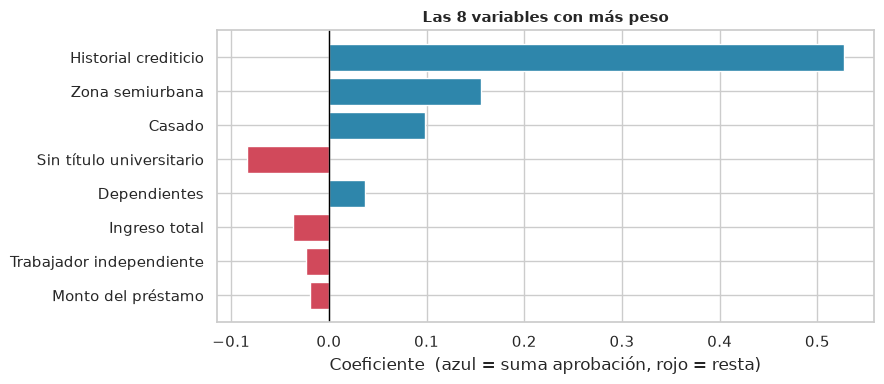

,variable,coeficiente
0,Historial crediticio,0.527
1,Zona semiurbana,0.155
2,Casado,0.098
3,Sin título universitario,-0.084
4,Dependientes,0.037
5,Ingreso total,-0.037
6,Trabajador independiente,-0.024
7,Monto del préstamo,-0.020


In [25]:
coeficientes = pd.Series(
    modelo_final.named_steps["modelo"].coef_[0],
    index=X.columns,
)

# Quitamos las categorías "Sin dato" para que el gráfico hable de variables reales
coeficientes = coeficientes[~coeficientes.index.str.contains("Sin dato")]
coeficientes = coeficientes.sort_values(key=abs, ascending=False).head(8)

nombres = {
    "Credit_History": "Historial crediticio",
    "Property_Area_Semiurban": "Zona semiurbana",
    "Property_Area_Urban": "Zona urbana",
    "Married_Yes": "Casado",
    "Married_Sin dato": "Estado civil sin dato",
    "Education_Not Graduate": "Sin título universitario",
    "Ingreso_Total": "Ingreso total",
    "Dependents": "Dependientes",
    "Self_Employed_Yes": "Trabajador independiente",
    "LoanAmount": "Monto del préstamo",
    "Loan_Amount_Term": "Plazo",
    "Gender_Male": "Hombre",
    "Gender_Sin dato": "Género sin dato",
    "Self_Employed_Sin dato": "Empleo sin dato",
}

etiquetas = [nombres.get(col, col) for col in coeficientes.index]
valores = coeficientes.values
colores = [AZUL if valor > 0 else ROJO for valor in valores]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(etiquetas[::-1], valores[::-1], color=colores[::-1])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Coeficiente  (azul = suma aprobación, rojo = resta)")
ax.set_title("Las 8 variables con más peso")
plt.tight_layout()
plt.show()

pd.DataFrame({"variable": etiquetas, "coeficiente": valores.round(3)})

- **Historial crediticio (0,53):** con diferencia, la que más empuja a aprobar.
- **Zona semiurbana (0,16)** y **casado (0,10):** suman un poco.
- **Sin título universitario (−0,08):** resta un poco.
- **Ingreso total (−0,04)** y **monto (−0,02):** casi no mueven la decisión cuando ya se conoce el historial.

Azul acerca a la aprobación, rojo aleja; el largo de la barra indica cuánto pesa.

Estos pesos describen **estos 614 datos**, no la vida real: el modelo no dice que casarse aumente la probabilidad de que aprueben un préstamo.

**¿Y SHAP?** SHAP reparte la "culpa" de una decisión entre las variables. En un modelo lineal no hace falta una librería: la predicción se descompone exactamente como **valor base + suma de contribuciones**. Cada variable suma o resta según su coeficiente y su valor en esa solicitud.

### 2. Explicación de una solicitud concreta

Se toma una solicitud rechazada del conjunto de prueba y se descompone su predicción.

In [26]:
caso = X_test[y_test == 0].iloc[[0]]
tabla_caso, base, log_odds, probabilidad = analisis.explicar_caso(modelo_final, caso)

print(f"Valor base del modelo (log-odds): {base:.2f}")
print(f"Suma de las contribuciones:       {log_odds - base:.2f}")
print(f"Predicción final (log-odds):      {log_odds:.2f}")
print(f"Probabilidad de aprobación:       {probabilidad:.2f}")
print(f"Decisión del modelo: {'APROBAR' if probabilidad >= 0.5 else 'RECHAZAR'}")
print("Resultado real: RECHAZAR")

tabla_caso["variable"] = tabla_caso["variable"].map(lambda v: nombres.get(v, v))
tabla_caso.round(3)

Valor base del modelo (log-odds): 0.10
Suma de las contribuciones:       -1.54
Predicción final (log-odds):      -1.44
Probabilidad de aprobación:       0.19
Decisión del modelo: RECHAZAR
Resultado real: RECHAZAR


,variable,valor,contribucion
3,Historial crediticio,0.0,-1.327
8,Casado,0.0,-0.134
12,Zona semiurbana,0.0,-0.120
9,Sin título universitario,0.0,0.045
0,Dependientes,0.0,-0.028
11,Trabajador independiente,0.0,0.009
13,Zona urbana,0.0,0.009
5,Hombre,1.0,-0.008


El modelo parte de un valor base de **0,10** (en escala *log-odds*) y las variables restan **1,54**: el resultado es **−1,44**, una probabilidad de aprobación de **0,19**. Como es menor que 0,5, **rechaza**, y acierta: el resultado real también era rechazar.

El **historial crediticio** resta **1,33**, mucho más que todas las demás juntas: esta persona no tenía historial y eso inclinó la balanza.

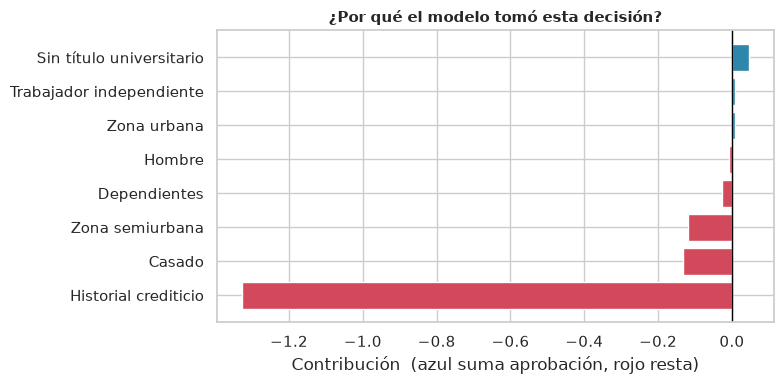

In [27]:
tabla_plot = tabla_caso.sort_values("contribucion")
colores = [AZUL if valor > 0 else ROJO for valor in tabla_plot["contribucion"]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tabla_plot["variable"], tabla_plot["contribucion"], color=colores)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Contribución  (azul suma aprobación, rojo resta)")
ax.set_title("¿Por qué el modelo tomó esta decisión?")
plt.tight_layout()
plt.show()

Cada barra es lo que una variable suma (azul) o resta (rojo). El historial es la barra roja más larga, la razón principal del rechazo; las demás casi no cambian el resultado.

El gráfico de coeficientes explica el modelo en general; este explica una sola decisión, la pregunta "¿por qué a mí?".

### 3. Guardar el modelo

El modelo son tres pasos encadenados: imputar, escalar y calcular la probabilidad. Se guarda completo para no repetir el proceso.

In [28]:
ruta = RAIZ / "modelo_entrenado.joblib"
joblib.dump(modelo_final, ruta)
print("Modelo guardado en:", ruta)

# Comprobar que se puede cargar
modelo_cargado = joblib.load(ruta)
print("Probabilidades de ejemplo:", modelo_cargado.predict_proba(X_test.head(3))[:, 1].round(2))

Modelo guardado en: /home/dilan/Work/proyecto_prestamos/modelo_entrenado.joblib
Probabilidades de ejemplo: [0.19 0.66 0.55]


Se guardó en `modelo_entrenado.joblib` y se volvió a cargar bien: las probabilidades de ejemplo son 0,19, 0,66 y 0,55.

El archivo incluye la imputación y el escalado, así que para predecir una solicitud nueva basta con cargarlo y pasarle los datos.

### 4. Conclusión

**Qué se hizo.** Se analizaron 614 solicitudes, se limpiaron y transformaron, se compararon tres modelos y se ajustó `C` con validación cruzada, enfocando el ajuste en los falsos negativos.

**Resultado.** La logística con `C = 0,01` y `class_weight="balanced"` es el modelo final: AUC 0,844, exactitud 84,6 %, recall 94,1 % y F1 0,894. Acierta 104 de 123 casos y deja fuera solo 5 aprobados reales (antes 10). El Random Forest se descartó por memorizar (AUC 1,00 en entrenamiento, 0,83 en prueba).

**Lectura de negocio.** El **historial crediticio** es la variable que más pesa (79,6 % de aprobación con historial, 7,9 % sin historial). La zona y el estado civil ajustan; el ingreso y el monto casi no cambian la decisión cuando ya se conoce el historial.

**Cómo usarlo.** Para **priorizar la revisión**, no para rechazar automáticamente: lo que el modelo aprueba pasa a verificación documental. Con ese proceso, un FP cuesta una revisión y un FN cuesta un cliente; por eso se aceptó el ajuste que reduce los FN a cambio de 3 FP más.

**Limitaciones.** 614 filas (491 / 123), un contexto y un momento concretos, y 50 solicitudes sin historial que se imputaron. Las métricas tienen variación y el modelo describe estos datos: no prueba causalidad ni predice el efecto de cambiar la política de crédito.

**Siguientes pasos.** Más datos, validación en otro periodo y definir con riesgo el costo real de cada error para fijar el umbral de forma explícita.